In [20]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from collections import Counter

nltk.download('stopwords')
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
print("All imports OK")

All imports OK


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\irush\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


- Task 1

In [22]:
folder = r'C:\Users\irush\OneDrive\Documents\Lab-01-Machine-Learning\data'

cols = ['text', 'label']
amazon = pd.read_csv(folder + r'\amazon_cells_labelled.txt', sep='\t', names=cols, quoting=3)
imdb   = pd.read_csv(folder + r'\imdb_labelled.txt',         sep='\t', names=cols, quoting=3)
yelp   = pd.read_csv(folder + r'\yelp_labelled.txt',         sep='\t', names=cols, quoting=3)

amazon['source'] = 'amazon'
imdb['source']   = 'imdb'
yelp['source']   = 'yelp'

df = pd.concat([amazon, imdb, yelp], ignore_index=True)
print(df.shape)
print(df['label'].value_counts())
df.head()

(3000, 3)
label
0    1500
1    1500
Name: count, dtype: int64


,text,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,amazon
4,The mic is great.,1,amazon


In [23]:
amazon

,text,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,amazon
4,The mic is great.,1,amazon
...,...,...,...
995,The screen does get smudged easily because it touches your ear and face.,0,amazon
996,What a piece of junk.. I lose more calls on this phone.,0,amazon
997,Item Does Not Match Picture.,0,amazon
998,The only thing that disappoint me is the infra red port (irda).,0,amazon


In [24]:
imdb

,text,label,source
0,"A very, very, very slow-moving, aimless movie about a distressed, drifting young man.",0,imdb
1,"Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.",0,imdb
2,"Attempting artiness with black & white and clever camera angles, the movie disappointed - became even more ridiculous - as the acting was poor and the plot and lines almost non-existent.",0,imdb
3,Very little music or anything to speak of.,0,imdb
4,The best scene in the movie was when Gerardo is trying to find a song that keeps running through his head.,1,imdb
...,...,...,...
995,I just got bored watching Jessice Lange take her clothes off!,0,imdb
996,"Unfortunately, any virtue in this film's production work was lost on a regrettable script.",0,imdb
997,"In a word, it is embarrassing.",0,imdb
998,Exceptionally bad!,0,imdb


In [25]:
yelp

,text,label,source
0,Wow... Loved this place.,1,yelp
1,Crust is not good.,0,yelp
2,Not tasty and the texture was just nasty.,0,yelp
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,1,yelp
4,The selection on the menu was great and so were the prices.,1,yelp
...,...,...,...
995,I think food should have flavor and texture and both were lacking.,0,yelp
996,Appetite instantly gone.,0,yelp
997,Overall I was not impressed and would not go back.,0,yelp
998,"The whole experience was underwhelming, and I think we'll just go to Ninja Sushi next time.",0,yelp


- Task 2 (Perform basic text preprocessing )

In [26]:
pd.set_option('display.max_colwidth', None)   # show full sentences

def clean_text(t):
    t = str(t).lower()                                   # 1. lowercase
    t = t.replace("’", "'")                              #    normalise curly apostrophes
    t = t.replace("won't", "will not").replace("can't", "can not")
    t = re.sub(r"n't\b", " not", t)                      #    keep negation: didn't -> did not
    t = t.replace("'", "")                               #    it's -> its
    t = re.sub(r"[^a-z\s]", " ", t)                      # 2. remove punctuation, digits, symbols
    t = re.sub(r"\s+", " ", t).strip()                   # 3. remove extra whitespace
    return t

df['clean_text'] = df['text'].apply(clean_text)          # 4. create clean-text column

# 5. Compare original and preprocessed text
df[['text', 'clean_text']].sample(5, random_state=1)

,text,clean_text
1957,"It showed exactly how the government and the scientist argued for humanity and the reasons of the ""gadget"".",it showed exactly how the government and the scientist argued for humanity and the reasons of the gadget
2087,All I have to say is the food was amazing!!!,all i have to say is the food was amazing
1394,"(My mother and brother had to do this)When I saw Robert Ryan portraying this type of man, it was a very good imitation of this type of individual, and I was impressed.",my mother and brother had to do this when i saw robert ryan portraying this type of man it was a very good imitation of this type of individual and i was impressed
1520,It is zillion times away from reality.,it is zillion times away from reality
1098,Ursula Burton's portrayal of the nun is both touching and funny at the same time with out making fun of nuns or the church.,ursula burtons portrayal of the nun is both touching and funny at the same time with out making fun of nuns or the church


In [27]:
example = "Wow...   I didn't like it!!  It's NOT 100% GREAT :)"
print("Original:", example)
print("Cleaned :", clean_text(example))

Original: Wow...   I didn't like it!!  It's NOT 100% GREAT :)
Cleaned : wow i did not like it its not great


- Test 3 (Explore the text data)

In [28]:
#Display positive and negative examples

print("POSITIVE EXAMPLES (label = 1):")
print(df[df.label == 1]['text'].sample(5, random_state=1).to_string(), "\n")
print("NEGATIVE EXAMPLES (label = 0):")
print(df[df.label == 0]['text'].sample(5, random_state=1).to_string())

POSITIVE EXAMPLES (label = 1):
174                                The file browser offers all the options that one needs.Handsfree is great.
137                                                                        My headset works just peachy-keen.
2476                                                                         We enjoy their pizza and brunch.
641                                                                                      Very wind-resistant.
2630    Four stars for the food & the guy in the blue shirt for his great vibe & still letting us in to eat ! 

NEGATIVE EXAMPLES (label = 0):
188                                                                                                                 Waste of 13 bucks.
160                                All I can do is whine on the Internet, so here it goes.The more I use the thing the less I like it.
2599                                                                                                           Not g

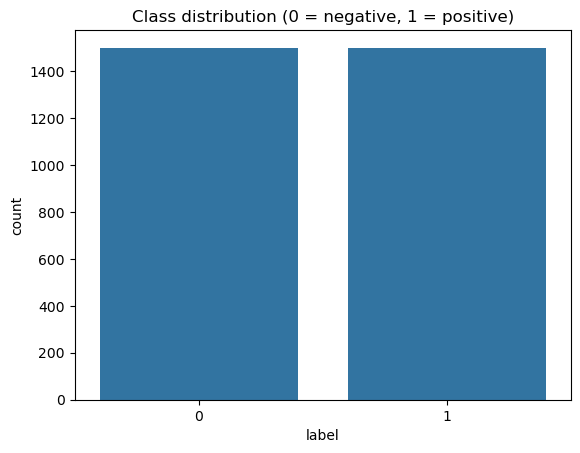

In [29]:
#Class balance

sns.countplot(x='label', data=df)
plt.title('Class distribution (0 = negative, 1 = positive)')
plt.show()

Top positive words: [('great', 201), ('good', 178), ('film', 103), ('phone', 87), ('movie', 85), ('one', 76), ('well', 68), ('best', 63), ('food', 60), ('place', 58), ('like', 56), ('love', 56), ('really', 56), ('service', 55), ('excellent', 52)]
Top negative words: [('bad', 100), ('movie', 96), ('phone', 78), ('one', 69), ('like', 69), ('food', 66), ('would', 64), ('time', 62), ('film', 57), ('place', 56), ('good', 53), ('service', 53), ('even', 48), ('back', 48), ('really', 47)]


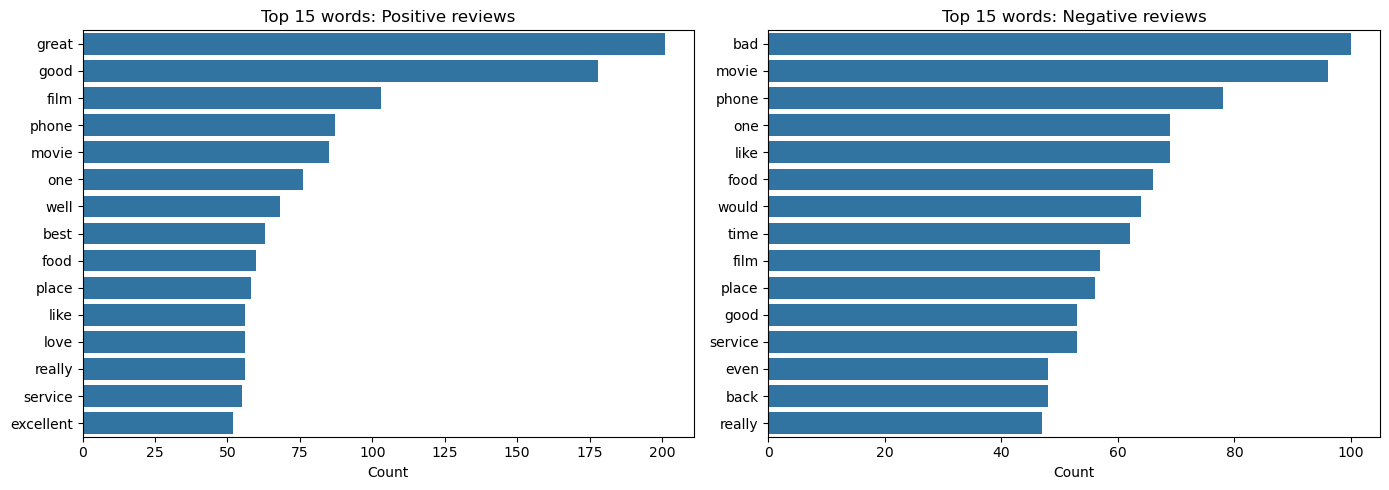

In [30]:
#Identify frequently occurring words

stop = set(stopwords.words('english'))

def top_words(series, n=15):
    words = ' '.join(series).split()
    words = [w for w in words if w not in stop and len(w) > 2]
    return Counter(words).most_common(n)

pos_top = top_words(df[df.label == 1]['clean_text'])
neg_top = top_words(df[df.label == 0]['clean_text'])

print("Top positive words:", pos_top)
print("Top negative words:", neg_top)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, data, title in zip(ax, [pos_top, neg_top], ['Positive', 'Negative']):
    w, c = zip(*data)
    sns.barplot(x=list(c), y=list(w), ax=a)
    a.set_title(f'Top 15 words: {title} reviews')
    a.set_xlabel('Count')
plt.tight_layout()
plt.show()

In [31]:
#Words that appear in both classes

pos_words = set(w for w, c in top_words(df[df.label == 1]['clean_text'], 30))
neg_words = set(w for w, c in top_words(df[df.label == 0]['clean_text'], 30))

print("Words common to both (top 30 each):", pos_words & neg_words)
print("Only in positive:", pos_words - neg_words)
print("Only in negative:", neg_words - pos_words)

Words common to both (top 30 each): {'movie', 'like', 'service', 'ever', 'one', 'good', 'film', 'time', 'really', 'place', 'phone', 'ive', 'food', 'also', 'even'}
Only in positive: {'nice', 'excellent', 'sound', 'best', 'love', 'great', 'quality', 'well', 'recommend', 'works', 'made', 'headset', 'price', 'amazing', 'product'}
Only in negative: {'money', 'much', 'would', 'terrible', 'disappointed', 'get', 'worst', 'waste', 'bad', 'work', 'could', 'make', 'minutes', 'never', 'back'}


label
0    11.99
1    11.82
Name: length, dtype: float64


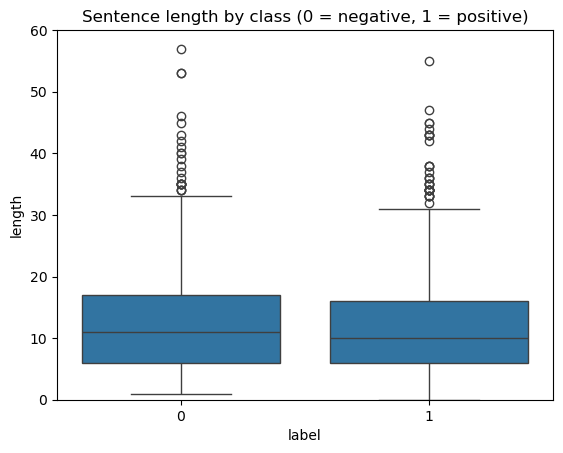

In [32]:
#Sentence length per class

df['length'] = df['clean_text'].str.split().str.len()
print(df.groupby('label')['length'].mean().round(2))

sns.boxplot(x='label', y='length', data=df)
plt.title('Sentence length by class (0 = negative, 1 = positive)')
plt.ylim(0, 60)
plt.show()

### Observations: positive vs negative reviews

- **Class balance:** Both classes contain 1500 sentences, so the dataset is balanced and accuracy is a fair metric.
- **Positive reviews** are dominated by praise words such as "great" (201), "good" (178), "best", "love" and "excellent". Words that appear only in the positive top 30 include "nice", "amazing", "recommend" and "quality".
- **Negative reviews** are led by "bad" (100) and include words that appear only in the negative top 30, such as "terrible", "worst", "waste", "disappointed", "never" and "money".
- **Shared words** such as "movie", "film", "phone", "food", "place" and "service" appear in both classes. They describe the domain (movies, phones, restaurants), not the sentiment, so they do not help separate the classes.
- **Sentence length:** The average length is almost the same for negative (11.99 words) and positive (11.82 words), so length is not a useful feature for this task. The boxplot shows a similar spread and a few long outliers in both classes.
- **Limitation:** The word "good" appears 53 times among the top negative words, probably in phrases such as "not good". This shows that counting individual words ignores context and negation, which is a known limitation of Bag-of-Words.

- Test 4 (Split the dataset)

In [33]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Train label counts:\n", y_train.value_counts())

Train size: 2400 | Test size: 600
Train label counts:
 label
1    1200
0    1200
Name: count, dtype: int64


- Task 5 (Create BOW representation)

In [34]:
vectorizer = CountVectorizer(max_features=5000)
X_train_bow = vectorizer.fit_transform(X_train)   # learn vocabulary from TRAIN only
X_test_bow  = vectorizer.transform(X_test)        # reuse the same vocabulary on TEST

print("Training matrix shape:", X_train_bow.shape)
print("Test matrix shape:", X_test_bow.shape)
print("Sample vocabulary:", vectorizer.get_feature_names_out()[:20])

Training matrix shape: (2400, 4504)
Test matrix shape: (600, 4504)
Sample vocabulary: ['aailiyah' 'abandoned' 'abhor' 'ability' 'able' 'abound' 'about' 'above'
 'abroad' 'absolute' 'absolutel' 'absolutely' 'absolutley' 'abstruse'
 'abysmal' 'ac' 'academy' 'accents' 'accept' 'acceptable']


- Task 6 (Train the models)

In [35]:
lr  = LogisticRegression(max_iter=1000)
svm = LinearSVC()

lr.fit(X_train_bow, y_train)
svm.fit(X_train_bow, y_train)
print("Both models trained")

Both models trained


- Task 7 (Evaluate performance)

===== Logistic Regression =====
Accuracy : 0.8217
Precision: 0.7988
Recall   : 0.86
F1-score : 0.8283
              precision    recall  f1-score   support

    Negative       0.85      0.78      0.81       300
    Positive       0.80      0.86      0.83       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600



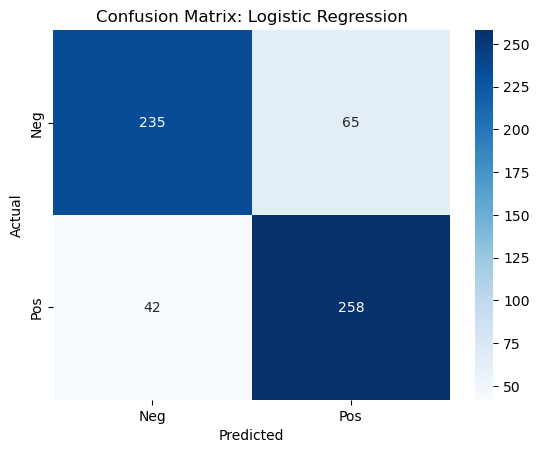

===== Linear SVM =====
Accuracy : 0.8017
Precision: 0.7751
Recall   : 0.85
F1-score : 0.8108
              precision    recall  f1-score   support

    Negative       0.83      0.75      0.79       300
    Positive       0.78      0.85      0.81       300

    accuracy                           0.80       600
   macro avg       0.80      0.80      0.80       600
weighted avg       0.80      0.80      0.80       600



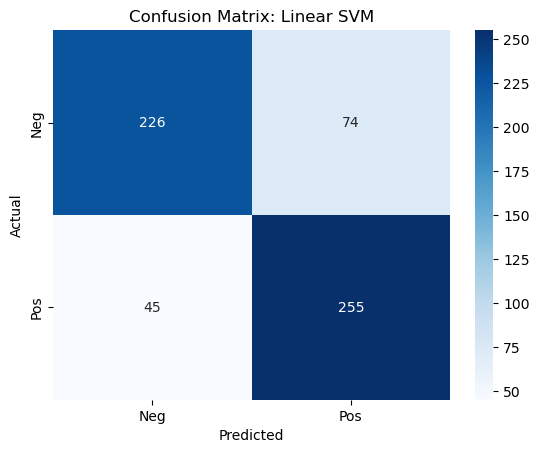

In [36]:
def evaluate(name, model):
    pred = model.predict(X_test_bow)
    print(f"===== {name} =====")
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall   :", round(recall_score(y_test, pred), 4))
    print("F1-score :", round(f1_score(y_test, pred), 4))
    print(classification_report(y_test, pred, target_names=['Negative', 'Positive']))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

evaluate('Logistic Regression', lr)
evaluate('Linear SVM', svm)

In [37]:
results = []
for name, model in [('Logistic Regression', lr), ('Linear SVM', svm)]:
    pred = model.predict(X_test_bow)
    results.append({
        'Model': name,
        'Accuracy':  round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall':    round(recall_score(y_test, pred), 4),
        'F1':        round(f1_score(y_test, pred), 4)
    })
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8217,0.7988,0.86,0.8283
1,Linear SVM,0.8017,0.7751,0.85,0.8108


In [38]:
pred = lr.predict(X_test_bow)
errors = pd.DataFrame({'text': X_test, 'actual': y_test, 'predicted': pred})
errors[errors.actual != errors.predicted].head(10)

,text,actual,predicted
2337,the burger i got the gold standard a burger and was kind of disappointed,0,1
2782,perfect for someone me who only likes beer ice cold or in this case even colder,1,0
302,someone shouldve invented this sooner,1,0
2415,gave up trying to eat any of the crust teeth still sore,0,1
576,the battery life is highly unacceptable,0,1
1413,the camera really likes her in this movie,1,0
2033,seems like a good quick place to grab a bite of some familiar pub food but do yourself a favor and look elsewhere,0,1
1963,the films dialogue is natural real to life,1,0
2927,it also took her forever to bring us the check when we asked for it,0,1
2739,never had anything to complain about here,1,0


- Task 8 (Test with new sentences)

In [39]:
def predict_sentiment(sentence, model):
    cleaned = clean_text(sentence)
    vec = vectorizer.transform([cleaned])
    return "Positive" if model.predict(vec)[0] == 1 else "Negative"

tests = [
    "I absolutely loved this movie, the acting was fantastic!",
    "The food was cold and the service was terrible.",
    "This phone has a great battery but the screen is awful.",
    "Not good at all.",
    "I wouldn't recommend this to anyone.",
    "It was okay, nothing special.",
    "The delivery was fast and the quality is excellent."
]

for s in tests:
    print(f"{s}\n   LR: {predict_sentiment(s, lr)} | SVM: {predict_sentiment(s, svm)}\n")

I absolutely loved this movie, the acting was fantastic!
   LR: Positive | SVM: Positive

The food was cold and the service was terrible.
   LR: Negative | SVM: Negative

This phone has a great battery but the screen is awful.
   LR: Positive | SVM: Positive

Not good at all.
   LR: Negative | SVM: Negative

I wouldn't recommend this to anyone.
   LR: Negative | SVM: Negative

It was okay, nothing special.
   LR: Negative | SVM: Negative

The delivery was fast and the quality is excellent.
   LR: Positive | SVM: Positive

